# US 02 · Channel-breakout momentum on US equities (S&P 1500-style universe)

This re-runs the ASX channel-breakout research (`../02_channel_breakout_research.ipynb`) on US stocks. Run `01_data_and_universe.ipynb` first.

**The key test is out-of-market.** The ASX rule was chosen on 2006–2016 ASX data: a 250-day entry channel, a 125-day exit channel, and trading at the next day's close. Here that exact rule is applied to US stocks **without retuning**. A rule that was overfitted to the ASX should fail on a market it never saw; a real effect should carry over. A horizon sweep is shown for context, but it is not used to pick anything.

**Contents**
1. Signal and backtest engine (identical to the ASX study)
2. Benchmarks
3. Time horizon
4. The ASX rule on US stocks
5. Costs
6. Legs and calendar years
7. Size control
8. Statistical tests vs random buy-and-hold
9. ASX vs US side by side
10. Conclusions

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import kurtosis, norm, skew

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
TRADING_DAYS = 252
IS, OOS = slice("2006-01-01", "2016-12-31"), slice("2017-01-01", None)
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a8a"
BLUE_LIGHT, BLUE_MID = "#cde2fb", "#86b6ef"

d = pd.read_pickle("data/clean.pkl")
spx = d["bench_ret"]["^GSPC"]
N, M = 250, 125          # the ASX rule, not re-optimised
print(f"{d['adj'].shape[1]} stocks, {d['adj'].index[0]:%Y-%m-%d} to {d['adj'].index[-1]:%Y-%m-%d}")

1718 stocks, 2005-01-03 to 2026-10-09


## 1. Signal and backtest engine

The code is unchanged from the ASX study:
* **Donchian state:** go long when the close breaks above the prior N-day high and exit below the prior M-day low; the short side is the mirror image. Positions are forced flat outside the universe.
* **Drift engine:** the long side holds +0.5 of capital and the short side −0.5. A new entry gets an equal share of its side, then positions drift with price, and every trade is charged.
* **Execution:** signals from day *t*'s close are traded at day *t+1*'s close (`lag=2`).

In [2]:
def channels(d, n):
    return (d["high"].rolling(n, min_periods=n).max().shift(1),
            d["low"].rolling(n, min_periods=n).min().shift(1))


def donchian_state(d, n, m=None):
    m = m or max(n // 2, 2)
    px, member = d["adj"], d["member"]
    up_n, lo_n = channels(d, n)
    up_m, lo_m = channels(d, m)

    def state(enter, leave):
        s = pd.DataFrame(np.nan, index=px.index, columns=px.columns)
        return s.mask(leave | ~member, 0.0).mask(enter & member, 1.0).ffill().fillna(0.0)

    return state(px > up_n, px < lo_m) - state(px < lo_n, px > up_m)


def backtest_drift(signal, d, scheme="neutral", cost_bps=20, lag=2, scale=None):
    sig = np.sign(signal.shift(lag - 1).fillna(0.0)).values if lag > 1 else np.sign(signal.fillna(0.0)).values
    r = d["ret"].reindex_like(signal).fillna(0.0).values
    k = np.ones(len(sig)) if scale is None else scale.reindex(signal.index).fillna(0.0).values
    sides = [(1, 0.5), (-1, 0.5)] if scheme == "neutral" else [(1, 1.0)]
    h = np.zeros(sig.shape[1])
    gross, turn = np.zeros(len(sig)), np.zeros(len(sig))
    for t in range(len(sig)):
        if t:
            pnl = h @ r[t]
            gross[t] = pnl
            h = h * (1 + r[t]) / (1 + pnl)
        new = np.zeros_like(h)
        for side, g in sides:
            g = g * k[t]
            on = sig[t] == side
            if not on.any() or g == 0:
                continue
            keep = on & (np.sign(h) == side) & (h != 0)
            enter = on & ~keep
            w_enter = g / on.sum()
            rest = g - w_enter * enter.sum()
            held = np.abs(h[keep]).sum()
            new[enter] = side * w_enter
            if keep.any():
                new[keep] = h[keep] * (rest / held if held > 0 else 0)
        turn[t] = np.abs(new - h).sum()
        h = new
    gross, turn = pd.Series(gross, signal.index), pd.Series(turn, signal.index)
    return pd.DataFrame({"gross": gross, "net": gross - turn * cost_bps / 1e4, "turnover": turn})


def stats(r, bench=None):
    r = r.dropna()
    ann_ret, ann_vol = r.mean() * TRADING_DAYS, r.std() * np.sqrt(TRADING_DAYS)
    eq = (1 + r).cumprod()
    out = {"ann_ret": ann_ret, "ann_vol": ann_vol, "sharpe": ann_ret / ann_vol, "max_dd": (eq / eq.cummax() - 1).min()}
    if bench is not None:
        b = bench.reindex(r.index).fillna(0.0)
        fit = sm.OLS(r, sm.add_constant(b)).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
        out.update(alpha=fit.params["const"] * TRADING_DAYS, alpha_t=fit.tvalues["const"], beta=fit.params.iloc[1])
    return pd.Series(out)


def report(series, bench, periods=(("IS", IS), ("OOS", OOS))):
    return pd.DataFrame({(name, per): stats(sr.loc[sl], bench) for name, sr in series.items() for per, sl in periods}).T

## 2. Benchmarks

* **S&P 500 (^GSPC):** the investable reference, used for beta. It is a price index (no dividends), like ^AXJO in the ASX study.
* **Equal-weight universe, drifting:** members are held with drifting weights and carry the same survivorship bias as the strategy. Alpha is measured against it.

In [3]:
ew = backtest_drift(d["member"].astype(float), d, "long", cost_bps=0, lag=1)["net"]
bench_table = pd.concat([report({"EW universe": ew}, spx), report({"S&P 500": spx}, None)])
bench_table.to_csv(RESULTS / "01_benchmark.csv")
bench_table[["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "beta"]]

ann_ret  ann_vol  sharpe  max_dd  alpha  beta
EW universe IS     0.131    0.231   0.568  -0.558  0.050 1.095
            OOS    0.155    0.215   0.723  -0.391 -0.003 1.093
S&P 500     IS     0.074    0.202   0.365  -0.568    NaN   NaN
            OOS    0.145    0.182   0.795  -0.339    NaN   NaN

## 3. Time horizon (context only)

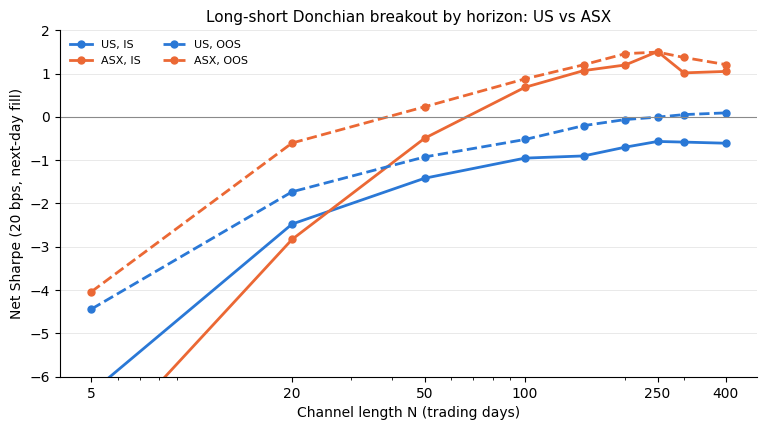

lag         1             2       
period     IS    OOS     IS    OOS
N                                 
5      -6.350 -4.300 -6.360 -4.440
20     -2.690 -1.820 -2.480 -1.730
50     -1.640 -0.980 -1.420 -0.930
100    -1.090 -0.550 -0.950 -0.520
150    -0.950 -0.210 -0.900 -0.200
200    -0.750 -0.070 -0.700 -0.060
250    -0.620 -0.020 -0.570 -0.010
300    -0.630  0.030 -0.580  0.050
400    -0.620  0.080 -0.610  0.090

In [4]:
rows = {}
for n in [5, 20, 50, 100, 150, 200, 250, 300, 400]:
    s_n = donchian_state(d, n)
    for lag in [1, 2]:
        bt = backtest_drift(s_n, d, "neutral", 20, lag)
        for per, sl in [("IS", IS), ("OOS", OOS)]:
            rows[(n, lag, per)] = stats(bt["net"].loc[sl], ew)
horizon = pd.DataFrame(rows).T.rename_axis(["N", "lag", "period"])
horizon.to_csv(RESULTS / "02_horizon_sweep.csv")

asx_h = pd.read_csv("../results/02_horizon_sweep.csv").set_index(["N", "lag", "period"])["sharpe"]
fig, ax = plt.subplots(figsize=(9, 4.5))
for per, ls in [("IS", "-"), ("OOS", "--")]:
    us = horizon.xs((2, per), level=("lag", "period"))["sharpe"]
    asx = asx_h.xs((2, per), level=("lag", "period")).reindex(us.index)
    ax.plot(us.index, us.values, color=BLUE, ls=ls, marker="o", ms=5, lw=2, label=f"US, {per}")
    ax.plot(asx.index, asx.values, color=ORANGE, ls=ls, marker="o", ms=5, lw=2, label=f"ASX, {per}")
ax.axhline(0, color=GREY, lw=0.8)
ax.set_xscale("log")
ax.set_xticks([5, 20, 50, 100, 250, 400], labels=[5, 20, 50, 100, 250, 400])
ax.set_ylim(-6, 2)
ax.set_xlabel("Channel length N (trading days)")
ax.set_ylabel("Net Sharpe (20 bps, next-day fill)")
ax.set_title("Long-short Donchian breakout by horizon: US vs ASX", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
ax.legend(fontsize=8, frameon=False, ncol=2)
fig.savefig(RESULTS / "horizon_us_vs_asx.png", dpi=130, bbox_inches="tight")
plt.show()
horizon["sharpe"].unstack(["lag", "period"]).round(2)

### Reading the sweep

* **Short horizons reverse in both markets.** At N=5 to 50 days the breakout loses money in the US as on the ASX.
* **Long-horizon momentum is missing in the US.** On the ASX the Sharpe turns clearly positive from about N=100 and reaches 1.5 at N=250. In the US it stays negative in-sample at every horizon (−0.6 at N=250) and only reaches about zero out-of-sample (−0.01 at N=250, +0.09 at N=400).
* **Execution timing barely matters in the US** (`lag=1` and `lag=2` are almost identical), unlike on the ASX. That fits tighter US spreads and less bid-ask bounce in closing prices.

## 4. The ASX rule on US stocks

N=250, M=125, next-day fill, 20 bps, with the same variants as the ASX study:

| Variant | Description |
|---|---|
| L/S, all names | longs and shorts across the whole universe |
| L/S, shorts in top 500 | shorts only in the 500 most liquid names; the US analogue of the ASX "top 200" restriction (US shorting is easier, so this matters less) |
| Long-only | breakout longs, fully invested |
| Long-only, S&P 500 hedge | long book minus rolling 126-day beta × S&P 500; in practice, short S&P 500 futures |
| L/S, 10% vol target | the L/S book scaled to 10% annualised volatility |

In [5]:
s = donchian_state(d, N, M)
rank = d["adv"].where(d["member"]).rank(axis=1, ascending=False)
top500 = (rank <= 500).shift(1, fill_value=False)
s_top = s.where((s > 0) | top500, 0.0)

books = {
    "L/S, all names": backtest_drift(s, d, "neutral", 20, 2)["net"],
    "L/S, shorts in top 500": backtest_drift(s_top, d, "neutral", 20, 2)["net"],
    "Long-only": backtest_drift(s, d, "long", 20, 2)["net"],
}
lo, m = books["Long-only"], spx.fillna(0.0)
cov = (lo * m).rolling(126, min_periods=60).mean() - lo.rolling(126, min_periods=60).mean() * m.rolling(126, min_periods=60).mean()
hb = (cov / m.rolling(126, min_periods=60).var()).shift(1).fillna(1.0)
books["Long-only, S&P 500 hedge"] = lo - hb * m - hb.diff().abs().fillna(0) * 2e-4
r_ls = books["L/S, all names"]
scale = (0.10 / (r_ls.rolling(63).std() * np.sqrt(TRADING_DAYS))).shift(1).clip(upper=3).fillna(0)
books["L/S, 10% vol target"] = backtest_drift(s, d, "neutral", 20, 2, scale=scale)["net"]

periods = (("IS", IS), ("OOS", OOS), ("FULL", slice("2006-01-01", None)))
final = report(books, ew, periods).join(report(books, spx, periods)[["alpha", "alpha_t", "beta"]].add_suffix("_spx"))
final.to_csv(RESULTS / "05_final_strategies.csv")
final[["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t", "alpha_spx", "beta_spx"]]

ann_ret  ann_vol  sharpe  max_dd  alpha  alpha_t  alpha_spx  beta_spx
L/S, all names           IS     -0.033    0.058  -0.568  -0.371 -0.022   -1.271     -0.026    -0.097
                         OOS    -0.001    0.080  -0.007  -0.213  0.009    0.416      0.008    -0.061
                         FULL   -0.018    0.069  -0.256  -0.438 -0.007   -0.527     -0.009    -0.082
L/S, shorts in top 500   IS     -0.014    0.065  -0.223  -0.349 -0.007   -0.362     -0.008    -0.092
                         OOS     0.001    0.083   0.009  -0.170  0.005    0.213      0.008    -0.052
                         FULL   -0.007    0.074  -0.098  -0.349 -0.001   -0.062      0.001    -0.075
Long-only                IS      0.080    0.209   0.384  -0.577 -0.034   -1.931      0.011     0.947
                         OOS     0.145    0.196   0.741  -0.369  0.012    0.614      0.007     0.952
                         FULL    0.111    0.203   0.546  -0.577 -0.013   -0.989      0.009     0.949
Long-only, S&P 500 hedge IS     -0.001    0.080  -0.014  -0.370 -0.011   -0.508     -0.001     0.004
                         OOS    -0.004    0.091  -0.042  -0.240 -0.019   -0.670     -0.001    -0.017
                         FULL   -0.002    0.086  -0.028  -0.370 -0.014   -0.824     -0.002    -0.005
L/S, 10% vol target      IS     -0.045    0.104  -0.432  -0.478 -0.034   -1.068     -0.038    -0.096
                         OOS     0.003    0.107   0.030  -0.260  0.014    0.474      0.012    -0.064
                         FULL   -0.022    0.105  -0.212  -0.514 -0.011   -0.506     -0.014    -0.082

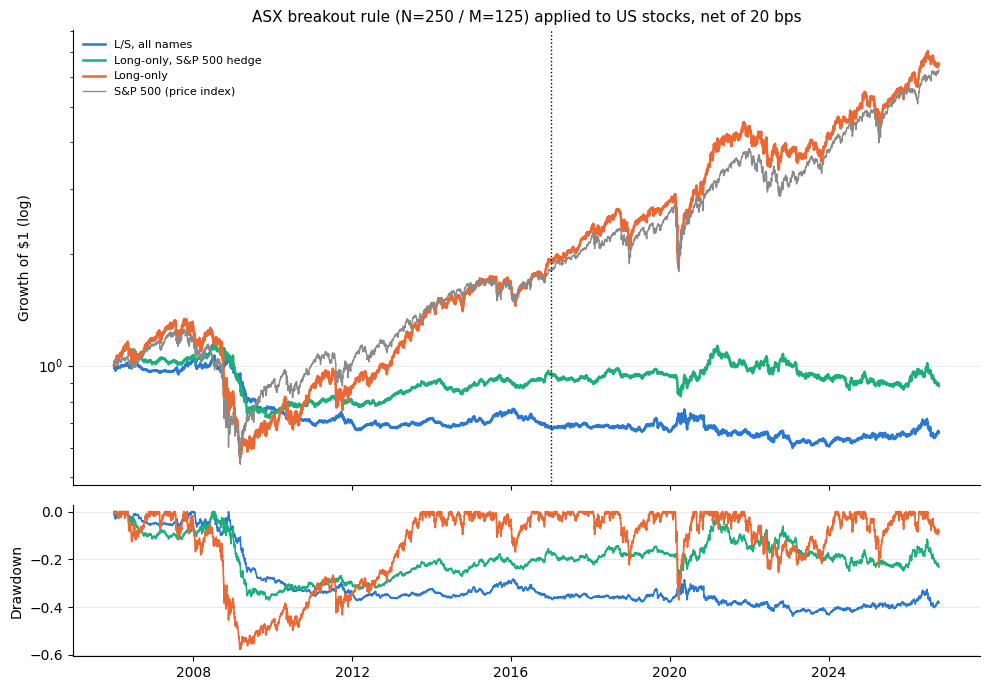

In [6]:
fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for name, c in zip(["L/S, all names", "Long-only, S&P 500 hedge", "Long-only"], [BLUE, AQUA, ORANGE]):
    eq = (1 + books[name].loc["2006":]).cumprod()
    axs[0].plot(eq, color=c, lw=1.8, label=name)
    axs[1].plot(eq / eq.cummax() - 1, color=c, lw=1.2)
axs[0].plot((1 + spx.loc["2006":].fillna(0)).cumprod(), color=GREY, lw=1, label="S&P 500 (price index)")
axs[0].axvline(pd.Timestamp("2017-01-01"), color="k", ls=":", lw=1)
axs[0].set_yscale("log")
axs[0].set_ylabel("Growth of $1 (log)")
axs[0].set_title("ASX breakout rule (N=250 / M=125) applied to US stocks, net of 20 bps", fontsize=11)
axs[0].legend(fontsize=8, frameon=False)
axs[1].set_ylabel("Drawdown")
for ax in axs:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", lw=0.6)
fig.tight_layout()
fig.savefig(RESULTS / "equity_curves.png", dpi=130)
plt.show()

### Reading the results

* **The L/S book has no edge in the US:** Sharpe −0.57 in-sample and −0.01 out-of-sample, with alpha indistinguishable from zero (t = −1.3 and 0.4). On the ASX the same rule earned Sharpe 1.5 in both periods.
* **Long-only is just the market.** Its Sharpe of 0.38 / 0.74 comes from equity beta (0.95). Against the equal-weight universe its alpha is −3.4% in-sample and +1.2% out-of-sample, neither significant. Hedging it with the S&P 500 leaves about zero.
* **The short leg is the main drag.** It lost money in most years of a long US bull market: −18% in 2009, −19% in 2010, −16% in 2016, −15% in 2019. Stocks hitting 250-day lows tended to recover rather than keep falling.
* **2009 momentum crash:** −23% for the L/S book, far worse than the ASX's −6%.

## 5. Costs

US large and mid caps trade at a 1-cent tick on prices that are mostly well above \$20, so realistic all-in costs are far below the brief's 20 bps. Shown for the L/S book: 0, 5 (realistic US), 20 (brief) and 50 bps.

In [7]:
costs = report({f"{c} bps": backtest_drift(s, d, "neutral", c, 2)["net"] for c in [0, 5, 20, 50]}, ew)
costs.to_csv(RESULTS / "06_costs.csv")
costs[["sharpe", "alpha", "alpha_t"]].unstack().round(3)

sharpe         alpha        alpha_t       
           IS    OOS     IS    OOS      IS    OOS
0 bps  -0.310  0.159 -0.007  0.022  -0.418  1.017
20 bps -0.568 -0.007 -0.022  0.009  -1.271  0.416
5 bps  -0.374  0.117 -0.011  0.019  -0.632  0.867
50 bps -0.954 -0.254 -0.045 -0.011  -2.518 -0.482

## 6. Legs and calendar years

In [8]:
legs = {"L/S": r_ls,
        "long leg": backtest_drift(s.clip(lower=0), d, "neutral", 20, 2)["net"],
        "short leg": backtest_drift(s.clip(upper=0), d, "neutral", 20, 2)["net"],
        "EW universe": ew, "S&P 500": spx}
yearly = pd.DataFrame(legs).loc["2006":].fillna(0)
yearly = yearly.groupby(yearly.index.year).apply(lambda x: (1 + x).prod() - 1)
yearly.to_csv(RESULTS / "07_yearly.csv")
print(f"L/S positive full years: {(yearly.loc[:2025, 'L/S'] > 0).sum()} of {len(yearly.loc[:2025])}")
yearly.style.format("{:.1%}").background_gradient(cmap="RdBu", vmin=-0.4, vmax=0.4, subset=["L/S", "long leg", "short leg"])

L/S positive full years: 8 of 20


,L/S,long leg,short leg,EW universe,S&P 500
date,,,,,
2006,-3.0%,8.8%,-11.2%,19.8%,13.6%
2007,6.5%,4.7%,0.9%,4.6%,3.5%
2008,-3.6%,-17.0%,11.5%,-34.2%,-38.5%
2009,-23.1%,-7.7%,-18.3%,29.7%,23.5%
2010,-9.2%,11.1%,-19.1%,27.0%,12.8%
2011,1.6%,0.6%,-0.9%,1.6%,-0.0%
2012,-3.5%,8.5%,-11.5%,21.8%,13.4%
2013,5.9%,19.9%,-12.1%,43.2%,29.6%
2014,-2.2%,5.5%,-7.7%,11.2%,11.4%


## 7. Size control

A second factor is added to the alpha regression: the equal-weight universe minus the equal-weight 500 most liquid names, both drifting.

In [9]:
ew500 = backtest_drift((d["member"] & top500).astype(float), d, "long", cost_bps=0, lag=1)["net"]
factors = pd.DataFrame({"ew": ew, "size": ew - ew500})
rows = {}
for name in ["L/S, all names", "L/S, shorts in top 500"]:
    for per, sl in [("IS", IS), ("OOS", OOS)]:
        fit = sm.OLS(books[name].loc[sl], sm.add_constant(factors.loc[sl].fillna(0))).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
        rows[(name, per)] = {"alpha": fit.params["const"] * TRADING_DAYS, "alpha_t": fit.tvalues["const"],
                             "beta_ew": fit.params["ew"], "beta_size": fit.params["size"]}
size_ctrl = pd.DataFrame(rows).T
size_ctrl.to_csv(RESULTS / "09_size_control.csv")
size_ctrl

alpha  alpha_t  beta_ew  beta_size
L/S, all names         IS  -0.020   -1.190   -0.077     -0.101
                       OOS -0.001   -0.057   -0.035     -0.560
L/S, shorts in top 500 IS  -0.015   -0.783   -0.077      0.436
                       OOS  0.002    0.070   -0.019     -0.186

## 8. Statistical tests vs random buy-and-hold

These are the same tests as in the ASX study (section 13 there):
* **Monte Carlo:** 1,000 random equal-weight buy-and-hold portfolios with the same number of names as the strategy's average long book.
* **Timing permutation:** each stock's signal is shifted by a random amount of time, keeping its trade count and holding periods. 100 permutations, so the p-value floor is about 0.01.
* **Paired block bootstrap:** stationary bootstrap, mean block 20 days, 2,000 resamples, testing the Sharpe difference against the median random portfolio.
* **Probabilistic Sharpe ratio:** because the rule was imported unchanged from the ASX, there was no search on US data. The plain PSR (hurdle 0) is therefore the right test for the *full* US sample, not just out-of-sample.

In [10]:
def ann_sharpe(x, axis=0):
    return x.mean(axis) / x.std(axis) * np.sqrt(TRADING_DAYS)


def psr(r):
    r = r.dropna()
    sr = r.mean() / r.std()
    z = sr * np.sqrt(len(r) - 1) / np.sqrt(1 - skew(r) * sr + (kurtosis(r, fisher=False) - 1) / 4 * sr ** 2)
    return norm.cdf(z)


def stationary_bootstrap_idx(T, B, mean_block, rng):
    idx = np.empty((B, T), dtype=np.int64)
    idx[:, 0] = rng.integers(0, T, B)
    jump = rng.random((B, T)) < 1 / mean_block
    fresh = rng.integers(0, T, (B, T))
    for t in range(1, T):
        idx[:, t] = np.where(jump[:, t], fresh[:, t], (idx[:, t - 1] + 1) % T)
    return idx


rng = np.random.default_rng(7)
ret0 = d["ret"].fillna(0.0)
k_match = int(round((s > 0).sum(axis=1).loc["2006":].mean()))
tested = {"Long-only": books["Long-only"], "L/S, all names": r_ls, "Long-only, S&P 500 hedge": books["Long-only, S&P 500 hedge"]}
rows = {}
for wname, start in [("FULL 2006-", "2006-01-03"), ("OOS 2017-", "2017-01-03")]:
    r_win = ret0.loc[start:]
    pool = np.flatnonzero(d["member"].loc[start:].iloc[0].values)
    growth = np.cumprod(1 + r_win.values, axis=0)
    picks = np.array([rng.choice(pool, k_match, replace=False) for _ in range(1000)])
    value = growth[:, picks].mean(axis=2) * (1 - 20e-4)
    rand = np.vstack([value[:1] - 1, value[1:] / value[:-1] - 1])
    rand_sh = ann_sharpe(rand)
    idx = stationary_bootstrap_idx(len(r_win), 2000, 20, rng)
    sub = rand[:, :200]
    for name, sr in tested.items():
        x = sr.loc[start:].values
        diffs = np.array([ann_sharpe(x[row]) - np.median(ann_sharpe(sub[row])) for row in idx])
        rows[(wname, name)] = {
            "Sharpe": ann_sharpe(x), "random B&H median Sharpe": np.median(rand_sh),
            "MC p (Sharpe)": (1 + (rand_sh >= ann_sharpe(x)).sum()) / 1001,
            "bootstrap ΔSharpe": ann_sharpe(x) - np.median(ann_sharpe(sub)),
            "ΔSharpe CI low": np.percentile(diffs, 2.5), "ΔSharpe CI high": np.percentile(diffs, 97.5),
            "bootstrap p": max(2 * min((diffs <= 0).mean(), (diffs >= 0).mean()), 1 / 2000),
            "PSR (Sharpe > 0)": psr(sr.loc[start:])}
tests = pd.DataFrame(rows).T
print(f"random portfolios hold K={k_match} names")
tests

random portfolios hold K=642 names


Sharpe  random B&H median Sharpe  MC p (Sharpe)  bootstrap ΔSharpe  ΔSharpe CI low  ΔSharpe CI high  bootstrap p  PSR (Sharpe > 0)
FULL 2006- Long-only                  0.546                     0.586          1.000             -0.039          -0.195            0.107        0.604             0.993
           L/S, all names            -0.256                     0.586          1.000             -0.842          -1.460           -0.176        0.011             0.120
           Long-only, S&P 500 hedge  -0.028                     0.586          1.000             -0.613          -1.123           -0.121        0.010             0.450
OOS 2017-  Long-only                  0.741                     0.685          0.001              0.057          -0.129            0.234        0.559             0.988
           L/S, all names            -0.007                     0.685          1.000             -0.691          -1.587            0.164        0.131             0.492
           Long-only, S&P 500 hedge  -0.042                     0.685          1.000             -0.726          -1.432           -0.090        0.032             0.448

In [11]:
prng = np.random.default_rng(5)
mem, sv0 = d["member"].values, s.values
T, n_cols = sv0.shape
perm = {"Long-only": [], "L/S, all names": []}
for _ in range(100):
    shifts = prng.integers(252, T - 252, n_cols)
    rows_idx = (np.arange(T)[:, None] - shifts[None, :]) % T
    sp = pd.DataFrame(np.where(mem, sv0[rows_idx, np.arange(n_cols)], 0.0), s.index, s.columns)
    perm["Long-only"].append(stats(backtest_drift(sp, d, "long", 20, 2)["net"].loc["2006":])["sharpe"])
    perm["L/S, all names"].append(stats(backtest_drift(sp, d, "neutral", 20, 2)["net"].loc["2006":])["sharpe"])
perm_table = pd.DataFrame({name: {"observed Sharpe": stats(tested[name].loc["2006":])["sharpe"],
                                  "null median": np.median(v), "null p95": np.percentile(v, 95),
                                  "p-value": (1 + (np.array(v) >= stats(tested[name].loc["2006":])["sharpe"]).sum()) / 101}
                           for name, v in perm.items()}).T
tests.to_csv(RESULTS / "11_significance.csv")
perm_table.to_csv(RESULTS / "11b_permutation.csv")
perm_table

,observed Sharpe,null median,null p95,p-value
Long-only,0.546,0.603,0.623,1.000
"L/S, all names",-0.256,-1.035,-0.763,0.010


### Reading the tests

* **Long-only vs random buy-and-hold:** no significant difference over the full sample (bootstrap p = 0.60). Out-of-sample its Sharpe is above every one of the 1,000 random portfolios (MC p = 0.001). That only says random 642-stock baskets have very similar Sharpes to each other in this one history; once time-sampling noise is included the difference (+0.06) is not significant (bootstrap p = 0.56).
* **L/S vs random buy-and-hold:** the L/S Sharpe is significantly *lower* over the full sample (bootstrap p = 0.01).
* **Timing permutation:** the real breakout timing beats random timing (p = 0.01), but only because random timing in this structure loses badly (median Sharpe −1.0). Beating a very bad null is not an edge.
* **PSR:** long-only Sharpe is above zero (0.99) thanks to the equity premium; the L/S book is not (0.12).

### Sanity check: is the US data broken, or is US momentum weak?

A rule that fails on new data could mean bad data or a bug. A quick independent check is classic **12-1 momentum** (Jegadeesh & Titman): each month, rank stocks on their return from 12 months ago to 1 month ago, buy the top decile and sell the bottom decile, equal weight, for one month. It is run on both datasets with the same code.

In [12]:
def classic_momentum(path):
    dd = pd.read_pickle(path)
    me = dd["adj"].ffill(limit=5).resample("ME").last()
    mem = dd["member"].resample("ME").last()
    mret = me.pct_change(fill_method=None)
    mom = (me.shift(1) / me.shift(12) - 1).where(mem)
    out = {}
    for t in range(13, len(me) - 1):
        sc = mom.iloc[t].dropna()
        if len(sc) < 100:
            continue
        q, nxt = sc.rank(pct=True), mret.iloc[t + 1]
        win, lose = nxt[q[q > 0.9].index].mean(), nxt[q[q < 0.1].index].mean()
        out[me.index[t + 1]] = {"winners - losers": win - lose, "winners - all": win - nxt[sc.index].mean()}
    return pd.DataFrame(out).T.fillna(0)


rows = {}
for mkt, path in [("US", "data/clean.pkl"), ("ASX", "../data/clean.pkl")]:
    cm = classic_momentum(path)
    for per, sl in [("IS", IS), ("OOS", OOS)]:
        x = cm.loc[sl]
        for col in x:
            rows[(mkt, per, col)] = {"ann_ret": x[col].mean() * 12, "sharpe": x[col].mean() / x[col].std() * np.sqrt(12)}
classic = pd.DataFrame(rows).T
classic.to_csv(RESULTS / "10_classic_momentum_check.csv")
classic["sharpe"].unstack(1).round(2)

IS   OOS
ASX winners - all     0.830 0.710
    winners - losers  0.590 1.110
US  winners - all    -0.170 0.720
    winners - losers -0.200 0.330

Classic 12-1 momentum tells the same story as the breakout rule: in the US it **lost money in 2006–2016** (winners minus losers, Sharpe −0.2) and was only modestly positive after 2017, while on the ASX it was strong in both periods (Sharpe 0.6 and 1.1). The data are fine. **US stock momentum was genuinely weak over this period**, which includes the 2009 momentum crash studied by Daniel & Moskowitz (2016). Australian momentum stayed strong.

## 9. ASX vs US side by side

Same rule, same costs, same engine. Alpha is against each market's own drifting equal-weight universe.

In [13]:
asx = pd.read_csv("../results/05_final_strategies.csv", index_col=[0, 1])
asx_hedge = pd.read_csv("../results/12a_beta_hedge.csv", index_col=[0, 1])
pairs = [("L/S, all names", ("Research L/S (all 500)", asx)),
         ("L/S, shorts in top 500", ("Implementable L/S (shorts top 200)", asx)),
         ("Long-only", ("Long-only", asx)),
         ("Long-only, S&P 500 hedge", ("Long-only, ASX 200 beta hedge", asx_hedge))]
rows = {}
for us_name, (asx_name, src) in pairs:
    for per in ["IS", "OOS"]:
        rows[(us_name, per, "US")] = final.loc[(us_name, per), ["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t"]]
        rows[(us_name, per, "ASX")] = src.loc[(asx_name, per), ["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t"]]
side = pd.DataFrame(rows).T
side.to_csv(RESULTS / "12_asx_vs_us.csv")
side.style.format({"ann_ret": "{:.1%}", "ann_vol": "{:.1%}", "sharpe": "{:.2f}", "max_dd": "{:.1%}",
                   "alpha": "{:.1%}", "alpha_t": "{:.1f}"})

## 10. Conclusions

1. **The ASX breakout rule does not carry over to the US.** Applied unchanged to an S&P 1500-style universe, the market-neutral book has no edge: Sharpe −0.57 in 2006–2016 and −0.01 in 2017–2026, against 1.5 and 1.5 on the ASX. Long-only breakouts just track the market.
2. **The failure is about the market, not the rule.** Classic 12-1 momentum shows the same pattern: weak in the US, strong on the ASX. Both families of momentum strategy agree, so the result is unlikely to be a quirk of the Donchian rule or of the parameters chosen on the ASX.
3. **What does carry over:** short horizons reverse in both markets.
4. **Why the markets might differ:** US large and mid caps are among the most heavily arbitraged stocks in the world, with tight spreads and many momentum funds competing for the same signal. The ASX 500 includes many small, resource-heavy, retail-traded stocks where trends can persist. The US short leg was also fighting a long bull market in which beaten-down stocks mostly recovered.
5. **What it means for the ASX result:** an out-of-market failure cannot rule out some overfitting of the ASX rule, but it doesn't show it either, because standard US momentum failed too. The ASX evidence still rests on its own out-of-sample test (2017–2026) and the significance tests in the ASX notebook.

**Caveats:** survivorship bias is larger for the US pool (index members plus only 216 removed names with data, some of whose tickers have been reused by other companies); costs of 20 bps are conservative for the US (5 bps is more realistic, but the edge is absent even at 0 bps); and the S&P 500 is a price index, so dividends are missing from the benchmark, as with the ASX 200.